### IPD441 - Visión por Computador
# Clase 7: Adversarial attacks
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción

Como ya sabemos, las redes neuronales profundas son una herramienta muy poderosa para reconocer patrones en datos y, por ejemplo, realizar clasificación de imágenes a nivel humano. 

<table border="1">
  <thead>
    <tr>
      <th>Model</th>
      <th>Size (MB)</th>
      <th>Top-1 Accuracy</th>
      <th>Top-5 Accuracy</th>
      <th>Parameters</th>
      <th>Depth</th>
      <th>Time (ms) per inference step (CPU)</th>
      <th>Time (ms) per inference step (GPU)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Xception</td>
      <td>88</td>
      <td>79.0%</td>
      <td>94.5%</td>
      <td>22.9M</td>
      <td>81</td>
      <td>109.4</td>
      <td>8.1</td>
    </tr>
    <tr>
      <td>VGG16</td>
      <td>528</td>
      <td>71.3%</td>
      <td>90.1%</td>
      <td>138.4M</td>
      <td>16</td>
      <td>69.5</td>
      <td>4.2</td>
    </tr>
    <tr>
      <td>VGG19</td>
      <td>549</td>
      <td>71.3%</td>
      <td>90.0%</td>
      <td>143.7M</td>
      <td>19</td>
      <td>84.8</td>
      <td>4.4</td>
    </tr>
 <tr>
      <td>InceptionV3</td>
      <td>92</td>
      <td>77.9%</td>
      <td>93.7%</td>
      <td>23.9M</td>
      <td>189</td>
      <td>42.2</td>
      <td>6.9</td>
    </tr>
    <tr>
      <td>InceptionResNetV2</td>
      <td>215</td>
      <td>80.3%</td>
      <td>95.3%</td>
      <td>55.9M</td>
      <td>449</td>
      <td>130.2</td>
      <td>10.0</td>
    </tr>
    <tr>
      <td>ResNet50</td>
      <td>98</td>
      <td>74.9%</td>
      <td>92.1%</td>
      <td>25.6M</td>
      <td>107</td>
      <td>58.2</td>
      <td>4.6</td>
    </tr>
  </tbody>
</table>

Sin embargo, aún no hemos probado cuán robustos son realmente estos modelos. ¿Podemos “engañar” al modelo? ¿Podemos diseñar imágenes que las redes clasifiquen siempre incorrectamente? 

# Adversarial attacks

Los "Adversarial attacks" son una técnica en la que se manipulan de forma intencionada las entradas de un modelo de inteligencia artificial para engañarlo.

<div align="center">
    <img src="img/adversarial_example.png" alt="" width="60%" align="center" />
</div>

# Conducción automática

Si bien esto parece al principio un juego divertido para engañar a las redes entrenadas, puede tener un impacto grave. Imagine que alguien que obtiene acceso a la entrada de la cámara del automóvil podría hacer que los peatones "desaparezcan" y el auto pensaría que la carretera está despejada.

<div align="center">
    <img src="img/adversarial_attacks_cityscapes_3.png" alt="" width="50%" align="center" />
</div>

# Señales de tránsito

Algunos tipos de ataques ni siquiera requieren agregar ruido, pero cambios menores en una señal de alto pueden ser suficientes para que la red la reconozca como una señal de velocidad de “50 km/h”.

<div align="center">
    <img src="img/StopSign.png" alt="" width="50%" align="center" />
</div>

# Problem Formulation

# What is Adversarial Attack?

El ataque adversario es un intento malicioso de perturbar un punto de datos $x_0 \in \mathbb{R}^d$ a otro punto $x \in \mathbb{R}^d$ de modo que $x$ pertenezca a cierta clase adversaria objetivo. En algunos escenarios, el objetivo puede no ser llevar $x_0$ a una clase objetivo específica $C_t$, sino simplemente alejarlo de su clase original $C_i$.

# Adversarial Attack Strategies

Se han propuesto muchas posibles estrategias para realizar ataques adversarios, que comparten el mismo objetivo: modificar la entrada de datos/imágenes solo un poco para tener un gran impacto en la predicción del modelo. Este es el mismo objetivo que tiene el generador en el marco de las Redes Generativas Adversarias (GANs): intentar engañar al discriminador cambiando su entrada.

Los ataques adversarios generalmente se agrupan en ataques de “caja blanca” y de “caja negra”.

- White-box attacks: tenemos acceso al parámetro del modelo y podemos, por ejemplo, calcular los gradientes con respecto a la entrada.
- Black-box attacks: no tenemos ningún conocimiento sobre la red y solo podemos obtener predicciones para una imagen, pero no gradientes o similares.

In [1]:
import os
import json
import numpy as np 
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [2]:
## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
# Torchvision
import torchvision
from torchvision import transforms

In [3]:
# Path to the folder where the pretrained models are saved
CHECKPOINT_PATH = "saved"
# Name of the model
MODEL_NAME = "inceptionv1"

In [4]:
# Fetching the device that will be used throughout this notebook
device = torch.device("cpu") if not torch.cuda.is_available() else torch.device("cuda:0")

In [5]:
# Load CNN architecture pretrained on ImageNet
os.environ["TORCH_HOME"] = CHECKPOINT_PATH
inceptionv1_model = torchvision.models.googlenet(weights='IMAGENET1K_V1')
inceptionv1_model = inceptionv1_model.to(device)

# No gradients needed for the network
inceptionv1_model.eval()
for p in inceptionv1_model.parameters():
    p.requires_grad = False

In [6]:
# Mean and Std from ImageNet
NORM_MEAN = np.array([0.5, 0.5, 0.5])
NORM_STD = np.array([0.5, 0.5, 0.5])
# No resizing and center crop necessary as images are already preprocessed.
plain_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN,
                         std=NORM_STD)
])

In [7]:
dataset = torchvision.datasets.ImageFolder(root="TinyImageNet/", transform=plain_transforms)

In [8]:
data_loader = data.DataLoader(dataset,          
                              batch_size=4, 
                              sampler=[652,1036,1942,4771],
                              shuffle=False, 
                              drop_last=False, 
                              num_workers=2)

In [9]:
# Load label names to interpret the label numbers 0 to 999
with open("TinyImageNet/label_list.json", "r") as f:
    label_names = json.load(f)
    
def get_label_index(lab_str):
    assert lab_str in label_names, f"Label \"{lab_str}\" not found."
    return label_names.index(lab_str)

In [10]:
from adversarial import *

In [11]:
exmp_batch, label_batch = next(iter(data_loader))
with torch.no_grad():
    preds = inceptionv1_model(exmp_batch.to(device))

# Ataques no dirigidos


# Fast Gradient Sign Method (FGSM)

Una de las primeras estrategias de ataque propuestas es el método de signo de gradiente rápido (FGSM), desarrollado por [Ian Goodfellow et al.](https://arxiv.org/pdf/1412.6572.pdf) en 2014. 
En el FGSM, se calcula la dirección en la cual la función de pérdida del modelo cambia más rápidamente con respecto a los cambios en los datos de entrada, y luego se modifica la entrada en esa dirección para generar una perturbación que engañe al modelo. Esta perturbación está diseñada para maximizar la pérdida o el error del modelo sin apuntar a una clase específica de salida.

El enfoque no está centrado en manipular la clasificación hacia una categoría determinada, sino más bien en inducir un error en la predicción sin un objetivo específico de clase. Por lo tanto, el Fast Gradient Sign Method se considera un tipo de ataque adversarial no dirigido o "untargeted attack".

# Formulación FGSM

Dada una imagen, creamos una ejemplo contradictorio mediante la siguiente expresión:

$$\tilde{x} = x + \epsilon \cdot \text{sign}(\nabla_x J(\theta,x,y))$$

El término $J(\theta,x,y)$ representa la pérdida de la red para clasificar la imagen de entrada $x$ como etiqueta $y$; $\epsilon$ es la intensidad del ruido, y $\tilde{x}$ el ejemplo adversario final. La ecuación se parece al SGD y en realidad no es más que eso. Cambiamos la imagen de entrada $x$ en la dirección de *maximizar* la pérdida $J(\theta,x,y)$. Esto es exactamente al revés que durante el entrenamiento, donde intentamos minimizar la pérdida.

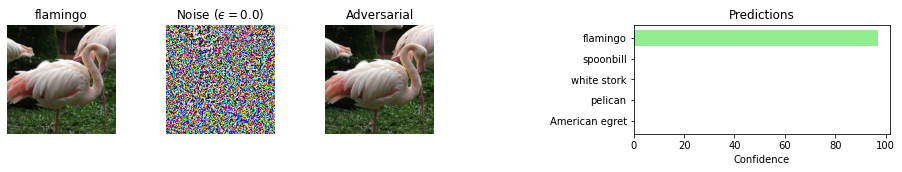

In [12]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=0, epsilon=0.0)

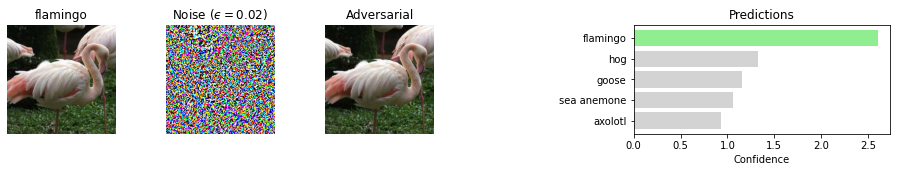

In [13]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=0, epsilon=0.02)

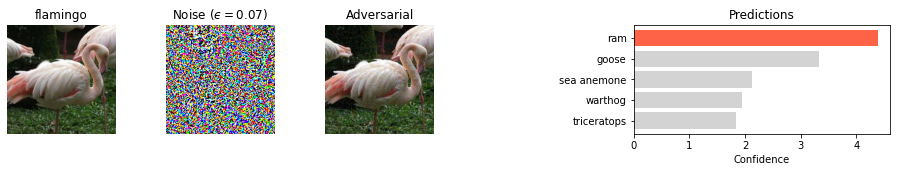

In [14]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=0, epsilon=0.07)

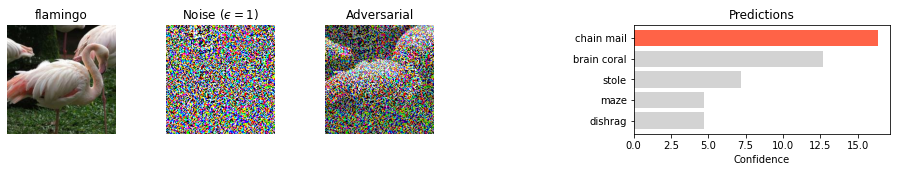

In [15]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=0, epsilon=1)

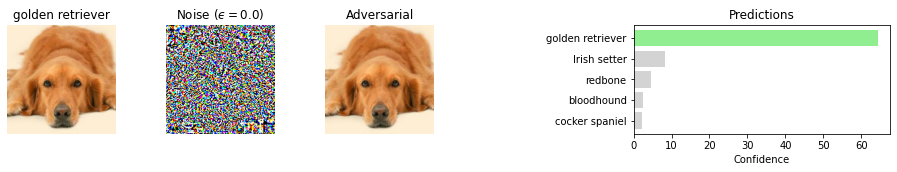

In [16]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=1, epsilon=0.0)

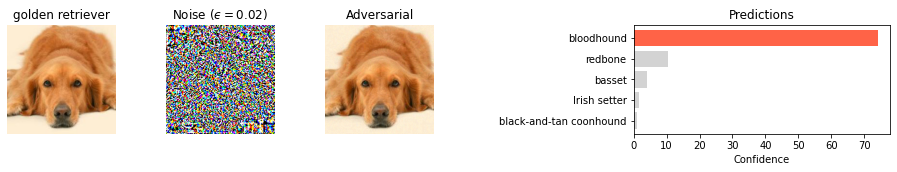

In [17]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=1, epsilon=0.02)

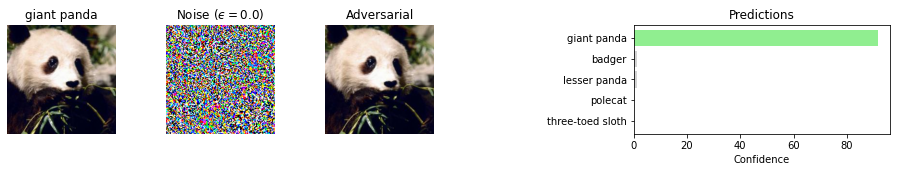

In [18]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=2, epsilon=0.0)

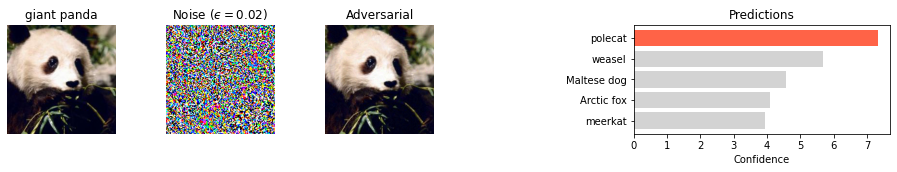

In [19]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=2, epsilon=0.02)

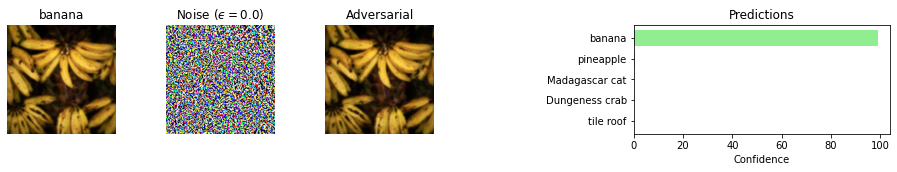

In [20]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=3, epsilon=0.0)

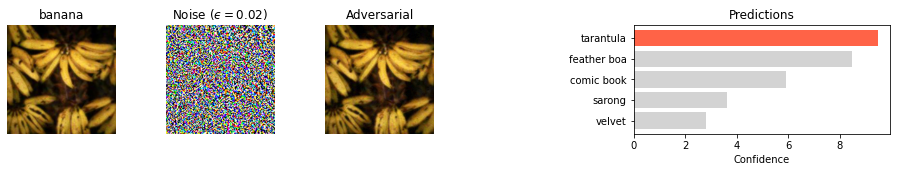

In [21]:
adversarial_attack_fgsm(inceptionv1_model, exmp_batch, label_batch, label_names, idx=3, epsilon=0.02)

# Ataques dirigidos

Se manipulan los datos de entrada con el objetivo específico de hacer que el modelo clasifique esos datos en una categoría particular elegida por el atacante. En otras palabras, en lugar de simplemente inducir un error en la clasificación, como en los ataques adversariales no dirigidos, aquí se busca que el modelo clasifique los datos de entrada en una clase específica determinada por el atacante.

<div align="center">
    <img src="img/targeted_untargeted.png" alt="" width="70%" align="center" />
</div>

# Adversarial Patches

En lugar de cambiar un poco cada píxel, también podemos crear un pequeño parche que cubra una parte menor de la imagen original pero que haga que el modelo prediga con seguridad una clase específica que elijamos. Esta forma de ataque es una amenaza aún mayor en aplicaciones del mundo real que FSGM. [Tom Brown et al. (2017)](https://arxiv.org/pdf/1712.09665.pdf) propusieron una forma de aprender de manera sólida estos parches de imágenes adversas.

<div align="center">
    <img src="img/adversarial_patches.jpg" alt="" width="40%" align="center" />
</div>

# ¿Cómo crear un parche?

La idea general es muy similar a FSGM en el sentido de que calculamos gradientes para la entrada y actualizamos nuestra entrada adversaria en consecuencia. Sin embargo, existen algunas diferencias: 

1. No calculamos un gradiente para cada píxel. En lugar de eso, reemplazamos partes de la imagen de entrada con nuestro parche y luego calculamos los gradientes solo para nuestro parche. 
2. No lo hacemos sólo para una imagen, sino que queremos que el parche funcione con cualquier imagen posible. Por lo tanto, tenemos un ciclo de entrenamiento completo en el que entrenamos el parche usando SGD. 
3. Los parches de imágenes generalmente están diseñados para hacer que el modelo prediga una clase específica, no cualquier otra clase arbitraria excepto la etiqueta verdadera.

In [22]:
# Load evaluation results of the pretrained patches
json_results_file = f"{CHECKPOINT_PATH}/patches_{MODEL_NAME}/patch_results.json"
json_results = {}
if os.path.isfile(json_results_file):
    with open(json_results_file, "r") as f:
        json_results = json.load(f)

# Ejemplo creación de parches para la clase tostador

In [23]:
class_names = ['toaster']
patch_sizes = [32, 64]
patch_dict = get_patches(inceptionv1_model, data_loader, class_names, patch_sizes, label_names, json_results)

Loaded weights for toaster size 32.
Loaded weights for toaster size 64.


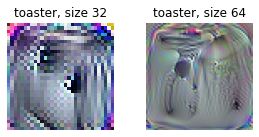

In [24]:
show_patches(class_names, patch_sizes, patch_dict)

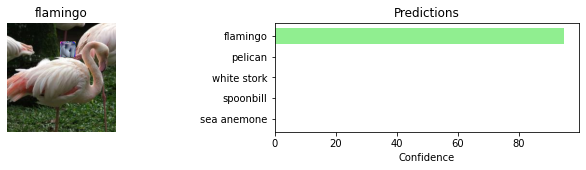

In [25]:
perform_patch_attack(patch_dict['toaster'][32]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 0)

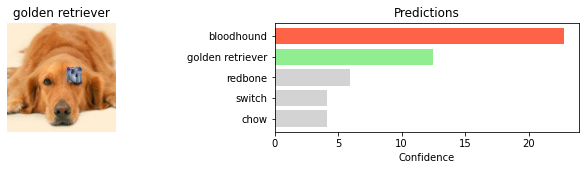

In [26]:
perform_patch_attack(patch_dict['toaster'][32]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 1)

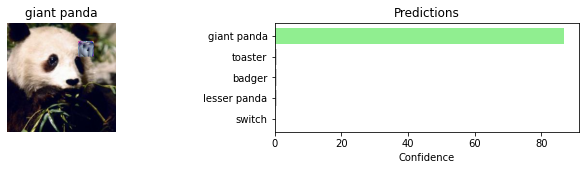

In [27]:
perform_patch_attack(patch_dict['toaster'][32]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 2)

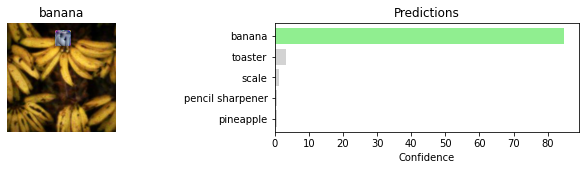

In [28]:
perform_patch_attack(patch_dict['toaster'][32]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 3)

In [29]:
show_table(patch_dict, class_names, 32)

Class name,Top-1 Patch size 32,Top-5 Patch size 32
toaster,56.25%,87.50%


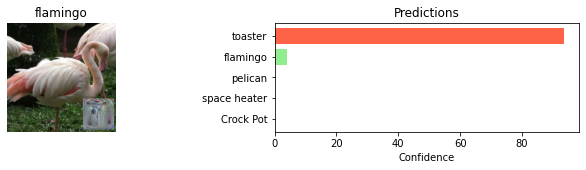

In [30]:
perform_patch_attack(patch_dict['toaster'][64]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 0)

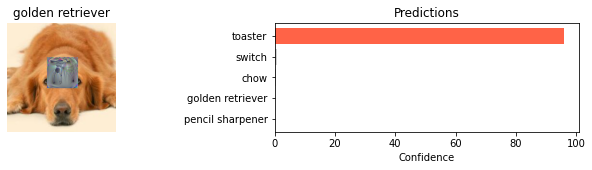

In [31]:
perform_patch_attack(patch_dict['toaster'][64]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 1)

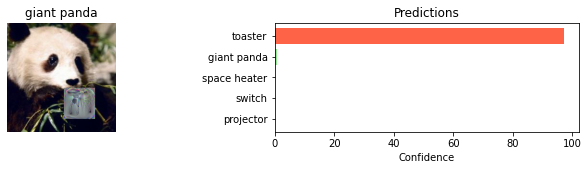

In [32]:
perform_patch_attack(patch_dict['toaster'][64]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 2)

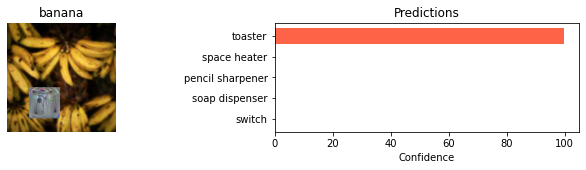

In [33]:
perform_patch_attack(patch_dict['toaster'][64]['patch'], inceptionv1_model, exmp_batch, label_batch, label_names, 3)

In [34]:
show_table(patch_dict, class_names, 64)

Class name,Top-1 Patch size 64,Top-5 Patch size 64
toaster,100.00%,100.00%


# Targeted Adversarial Attack

Un **ataque adversarial dirigido** implica la optimización de una perturbación aplicada a los datos de entrada para maximizar la probabilidad de que el modelo clasifique esos datos en una clase objetivo elegida por el atacante. Matemáticamente, esto se expresa como:

$$
\arg\min_{\delta} \quad ||\delta|| \quad \text{sujeto a} \quad f(x + \delta) = y_{target}
$$

donde:

$x$ es la imagen original, $\delta$ es la perturbación adversarial añadida, $f(x + \delta)$ es la clasificación del modelo para la imagen perturbada, $y_{target}$ es la clase objetivo del atacante.

El objetivo del ataque es encontrar una perturbación mínima  tal que el modelo asigne la imagen a la clase objetivo.

In [35]:
inceptionv3_model = torchvision.models.inception_v3(weights='DEFAULT')
_ = inceptionv3_model.to(device).eval()

In [36]:
loader = transforms.Compose([transforms.Resize([299, 299]), transforms.ToTensor()])

def load_dataset(data_path):
    data_path = data_path
    train_dataset = torchvision.datasets.ImageFolder(
        root=data_path,
        transform=loader
    )
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=9,
        num_workers=0,
        shuffle=False
    )
    return train_loader

In [37]:
with open("imagenet_class_index.json", "r") as classes:
    class_idx = json.load(classes)

# Creación de la Perturbación Adversarial Dirigida

Aquí, se genera la imagen adversarial restando $\epsilon \cdot \nabla J(x)$; donde $J(x)$ es el gradiente de la función de pérdida con respecto a la imagen, y $\epsilon$ es un hiperparámetro que controla la intensidad de la perturbación.

In [ ]:
def targeted_adversary(image, epsilon, gradient):
    
    # Similar a lo anterior, pero ahora estamos minimizando el error!
    perturbed_image = image - epsilon * gradient
    
    # Asegura que los valores de los píxeles permanezcan dentro del rango válido [0,1].
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
  
    return perturbed_image

In [38]:
test_data, _ = list(load_dataset("test"))[0]

# Ejemplo ataque adversario dirigido a la clase 340 (zebra)

In [39]:
prediction_names,adversarial_examples = create_adversarial_examples(test_data,
                                                                    inceptionv3_model,
                                                                    class_idx,
                                                                    target_class = 340)

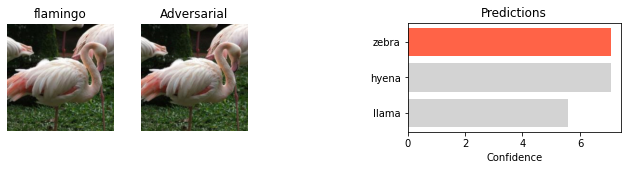

In [40]:
adversarial_prediction(test_data, 0, inceptionv3_model, class_idx, prediction_names, adversarial_examples)

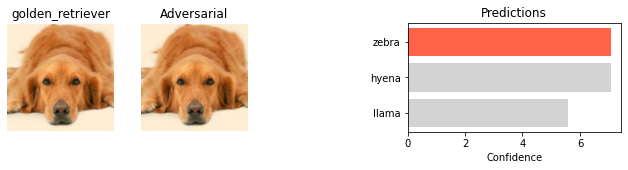

In [41]:
adversarial_prediction(test_data, 1, inceptionv3_model, class_idx, prediction_names, adversarial_examples)

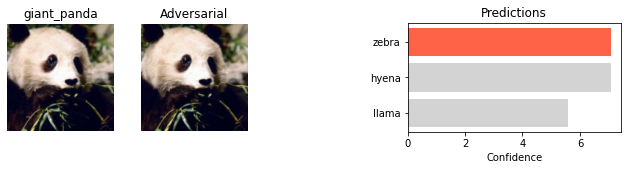

In [42]:
adversarial_prediction(test_data, 2, inceptionv3_model, class_idx, prediction_names, adversarial_examples)

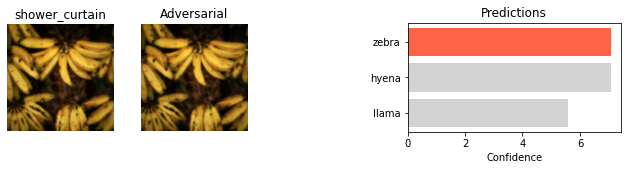

In [43]:
adversarial_prediction(test_data, 3, inceptionv3_model, class_idx, prediction_names, adversarial_examples)

# Ataques Tipográficos (Typographic Attacks)

Un *ataque tipográfico* es un tipo de ataque adversarial en el que una palabra engañosa es añadida a una imagen para influir en la predicción de un modelo de visión por computadora. Estos ataques explotan la capacidad de los modelos multimodales, como CLIP, para asociar texto con imágenes.

Como hemos visto, CLIP está lleno de neuronas multimodales que responden tanto a imágenes como a texto para un concepto determinado. Dada la fuerza con la que estas neuronas reaccionan al texto, son particularmente susceptibles a estos ataques.

In [44]:
# pip install ftfy

In [45]:
# pip install git+https://github.com/openai/CLIP.git

In [46]:
import clip
import torch
from torchvision import models

In [47]:
from typographic import *

In [48]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [49]:
# Load ImageNet labels
imagenet_labels = []
with open("ImageNetLabels.txt", "r") as file:
    for line in file:
        label = line.strip()
        imagenet_labels.append(label)
text_inputs = torch.cat([clip.tokenize(f"a photo of {label}") for label in imagenet_labels]).to(device)

# Ejemplo con modelo CLIP RN50x4

In [50]:
# Load the RN50-x4 model
RN50x4, RN50x4_preprocess = clip.load('RN50x4', device)

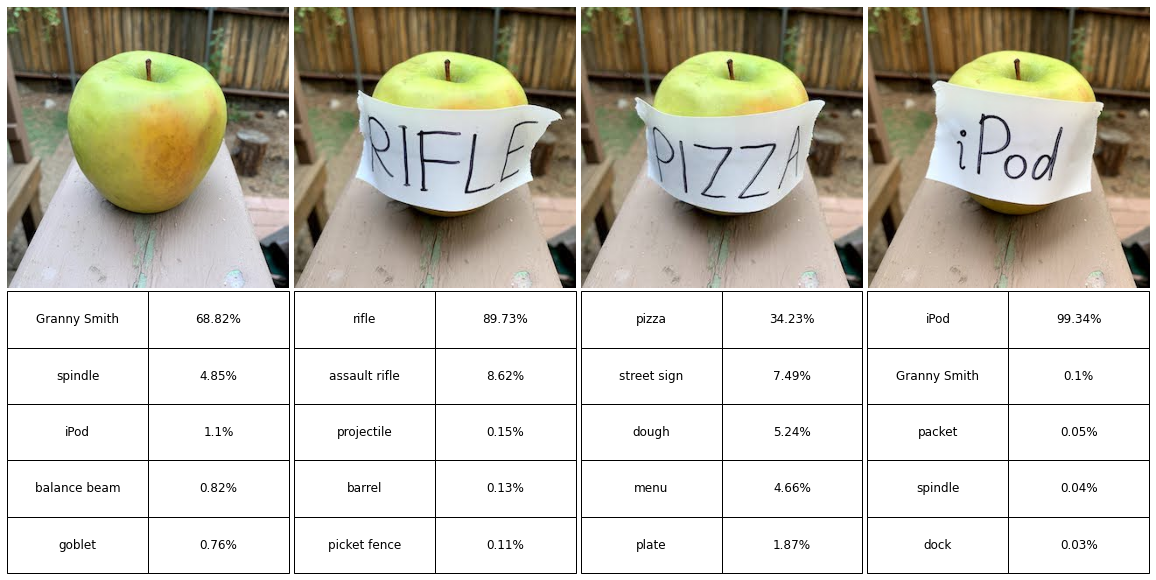

In [51]:
typographic_attack(RN50x4, RN50x4_preprocess, "test/apple", text_inputs, imagenet_labels)

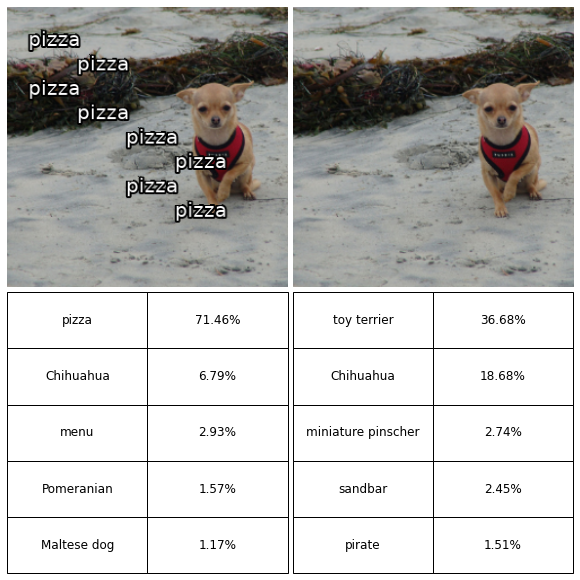

In [52]:
typographic_attack(RN50x4, RN50x4_preprocess, "test/chihuahua", text_inputs, imagenet_labels)

#  Stroop Effect

El efecto Stroop es el retraso en el tiempo de reacción del cerebro ante ciertos estimulos incongruentes. Por ejemplo, reconocer un color "mal etiquetado" (<font color='blue'>verde</font>, <font color='red'>azul</font>, <font color='green'>rojo</font>) es más difícil de lo normal. 

Utilizando la clasificación zero-shot de CLIP con el prompt "my favorite word, written in the color _____", es posible apreciar que, a diferencia de los humanos que nos tomamos más tiempo para responder correctamente, CLIP muestra una tasa de error más alta.

In [53]:
color_list = []
with open("colors.txt", "r") as file:
    for line in file:
        label = line.strip()
        color_list.append(label)
color_inputs = torch.cat([clip.tokenize(f"my favorite word, written in the color {color}") 
                         for color in color_list]).to(device)

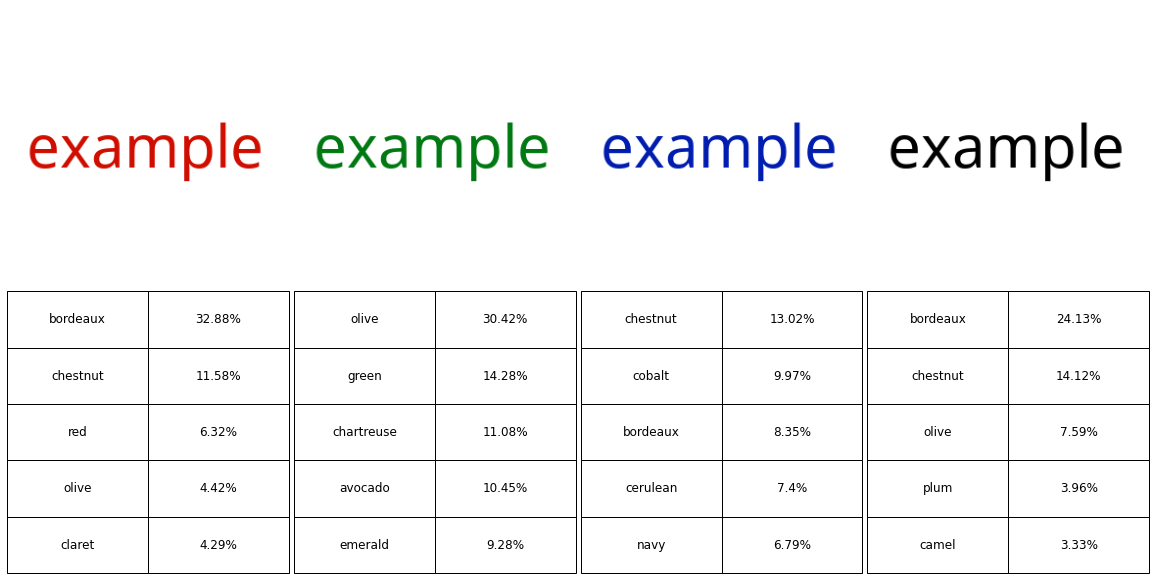

In [54]:
typographic_attack(RN50x4, RN50x4_preprocess, "test/stroop/example", color_inputs, color_list)

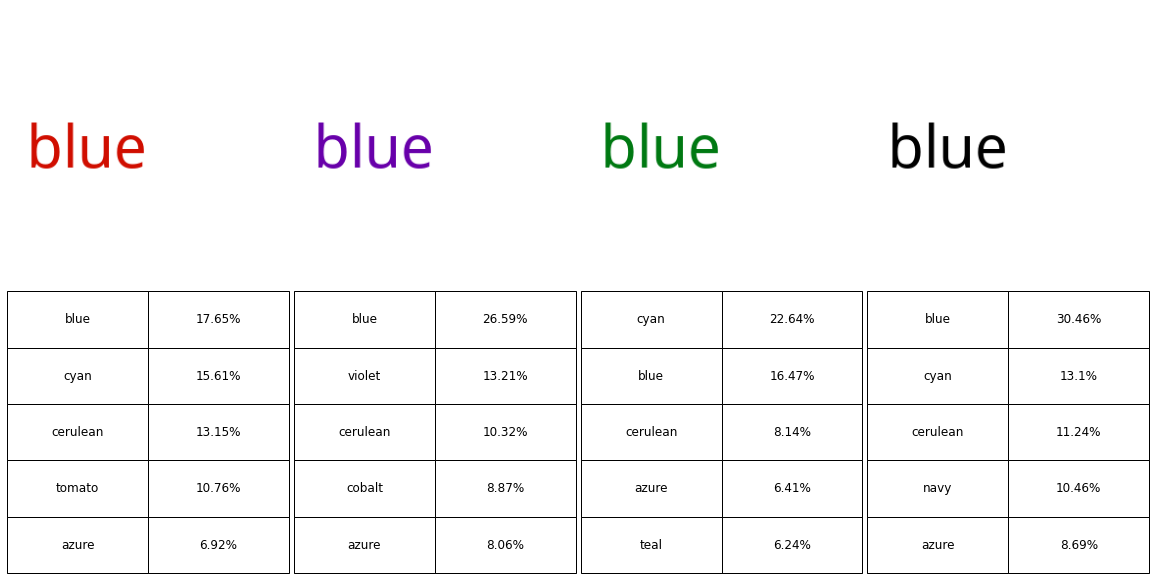

In [55]:
typographic_attack(RN50x4, RN50x4_preprocess, "test/stroop/blue", color_inputs, color_list)

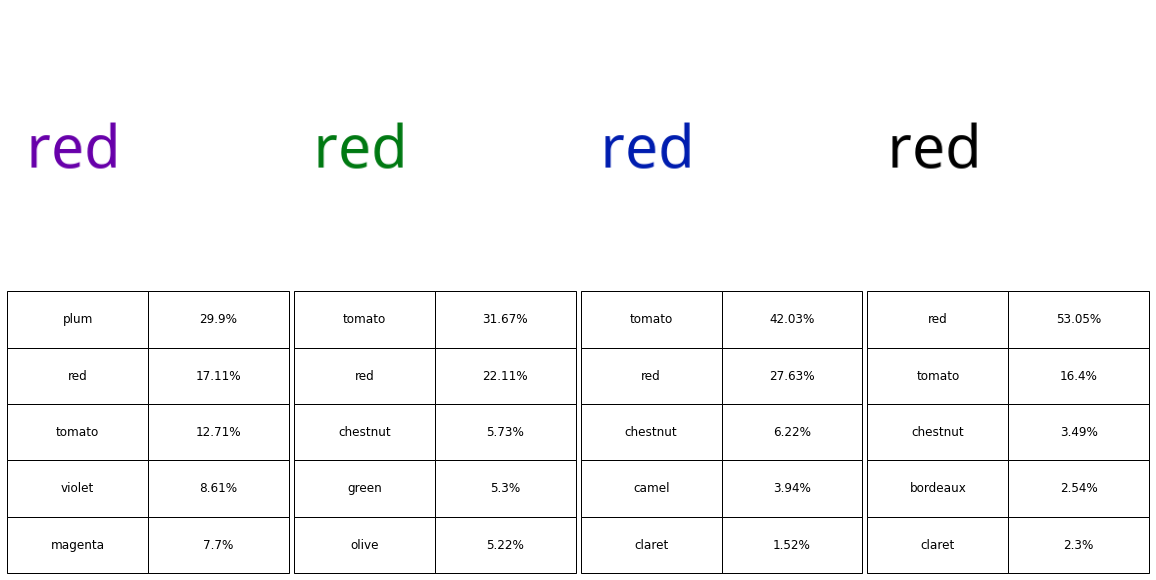

In [56]:
typographic_attack(RN50x4, RN50x4_preprocess, "test/stroop/red", color_inputs, color_list)